In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv(
    "../dataset/household_power_consumption.txt",
    sep=";",
    na_values=["?"]
)

In [4]:
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [5]:
df.shape

(2075259, 9)

In [6]:
df.columns

Index(['Date', 'Time', 'Global_active_power', 'Global_reactive_power',
       'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2',
       'Sub_metering_3'],
      dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   str    
 1   Time                   str    
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), str(2)
memory usage: 176.0 MB


In [8]:
df.isnull().sum()

Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

In [9]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

Date                     0.000000
Time                     0.000000
Global_active_power      1.251844
Global_reactive_power    1.251844
Voltage                  1.251844
Global_intensity         1.251844
Sub_metering_1           1.251844
Sub_metering_2           1.251844
Sub_metering_3           1.251844
dtype: float64


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.dtypes

Date                         str
Time                         str
Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object

In [12]:
df['Date'] = pd.to_datetime(
    df['Date'],
    format='%d/%m/%Y',
    errors='coerce'
)

In [13]:
df.dtypes

Date                     datetime64[us]
Time                                str
Global_active_power             float64
Global_reactive_power           float64
Voltage                         float64
Global_intensity                float64
Sub_metering_1                  float64
Sub_metering_2                  float64
Sub_metering_3                  float64
dtype: object

In [14]:
cols = [
    'Global_active_power',
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3'
]

for col in cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

In [15]:
df.describe()

,Date,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2075259,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06
mean,2008-12-05 19:13:27.255186,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00
min,2006-12-16 00:00:00,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00
25%,2007-12-12 00:00:00,3.080000e-01,4.800000e-02,2.389900e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2008-12-06 00:00:00,6.020000e-01,1.000000e-01,2.410100e+02,2.600000e+00,0.000000e+00,0.000000e+00,1.000000e+00
75%,2009-12-01 00:00:00,1.528000e+00,1.940000e-01,2.428900e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01
max,2010-11-26 00:00:00,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01
std,NaN,1.057294e+00,1.127220e-01,3.239987e+00,4.444396e+00,6.153031e+00,5.822026e+00,8.437154e+00


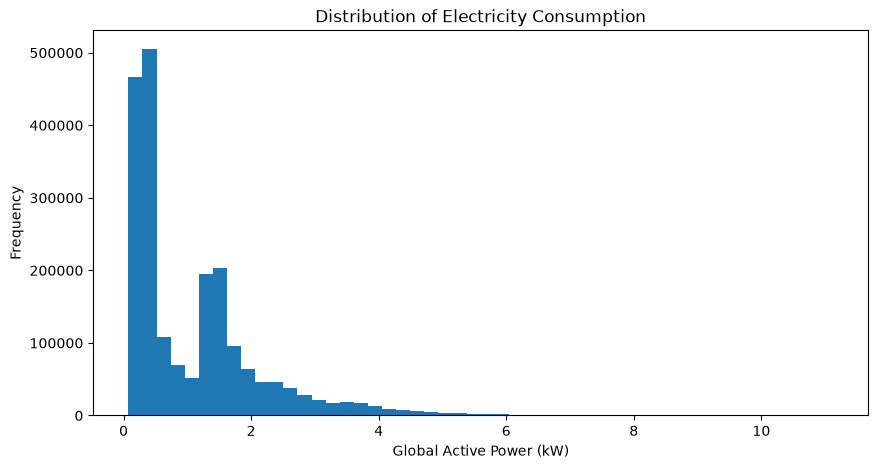

In [16]:
plt.figure(figsize=(10,5))

plt.hist(
    df['Global_active_power'].dropna(),
    bins=50
)

plt.xlabel('Global Active Power (kW)')
plt.ylabel('Frequency')
plt.title('Distribution of Electricity Consumption')

plt.show()

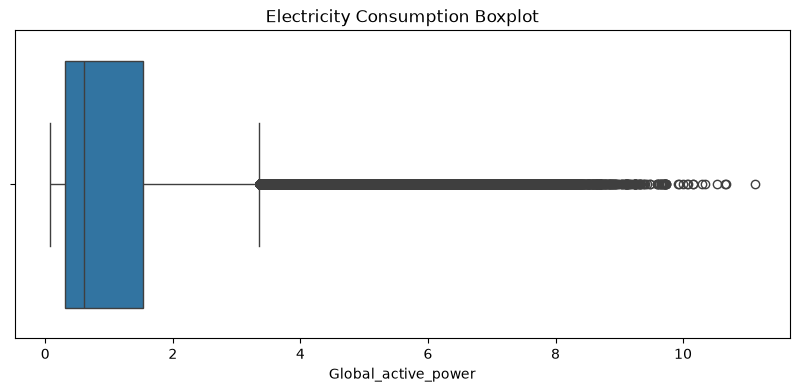

In [17]:
plt.figure(figsize=(10,4))

sns.boxplot(x=df['Global_active_power'])

plt.title('Electricity Consumption Boxplot')

plt.show()

In [18]:
df['energy_kwh'] = df['Global_active_power'] / 60

In [19]:
numeric_cols = df.select_dtypes(include='number').columns

missing_rows = df[numeric_cols].isnull().all(axis=1).sum()

print("Rows where all measurements are missing:", missing_rows)

Rows where all measurements are missing: 25979


In [20]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [21]:
print("Starting date:", df['Date'].min())
print("Ending date:", df['Date'].max())

Starting date: 2006-12-16 00:00:00
Ending date: 2010-11-26 00:00:00


In [22]:
df['datetime'] = pd.to_datetime(
    df['Date'].dt.strftime('%Y-%m-%d') + ' ' + df['Time'],
    errors='coerce'
)

df[['Date', 'Time', 'datetime']].head()

,Date,Time,datetime
0,2006-12-16,17:24:00,2006-12-16 17:24:00
1,2006-12-16,17:25:00,2006-12-16 17:25:00
2,2006-12-16,17:26:00,2006-12-16 17:26:00
3,2006-12-16,17:27:00,2006-12-16 17:27:00
4,2006-12-16,17:28:00,2006-12-16 17:28:00


In [23]:
minute_data = df[
    ['datetime', 'Global_active_power']
].dropna(subset=['datetime'])

minute_data = minute_data.set_index('datetime').sort_index()

In [24]:
hourly_count = minute_data['Global_active_power'].resample('h').count()

print(hourly_count.head(10))

datetime
2006-12-16 17:00:00    36
2006-12-16 18:00:00    60
2006-12-16 19:00:00    60
2006-12-16 20:00:00    60
2006-12-16 21:00:00    60
2006-12-16 22:00:00    60
2006-12-16 23:00:00    60
2006-12-17 00:00:00    60
2006-12-17 01:00:00    60
2006-12-17 02:00:00    60
Freq: h, Name: Global_active_power, dtype: int64


In [25]:
hourly_power = minute_data['Global_active_power'].resample('h').mean()

hourly_energy = hourly_power[hourly_count >= 45]

hourly_df = pd.DataFrame({
    'energy_kwh': hourly_energy
})

print(hourly_df.head())
print(hourly_df.shape)

                     energy_kwh
datetime                       
2006-12-16 18:00:00    3.632200
2006-12-16 19:00:00    3.400233
2006-12-16 20:00:00    3.268567
2006-12-16 21:00:00    3.056467
2006-12-16 22:00:00    2.200133
(34151, 1)


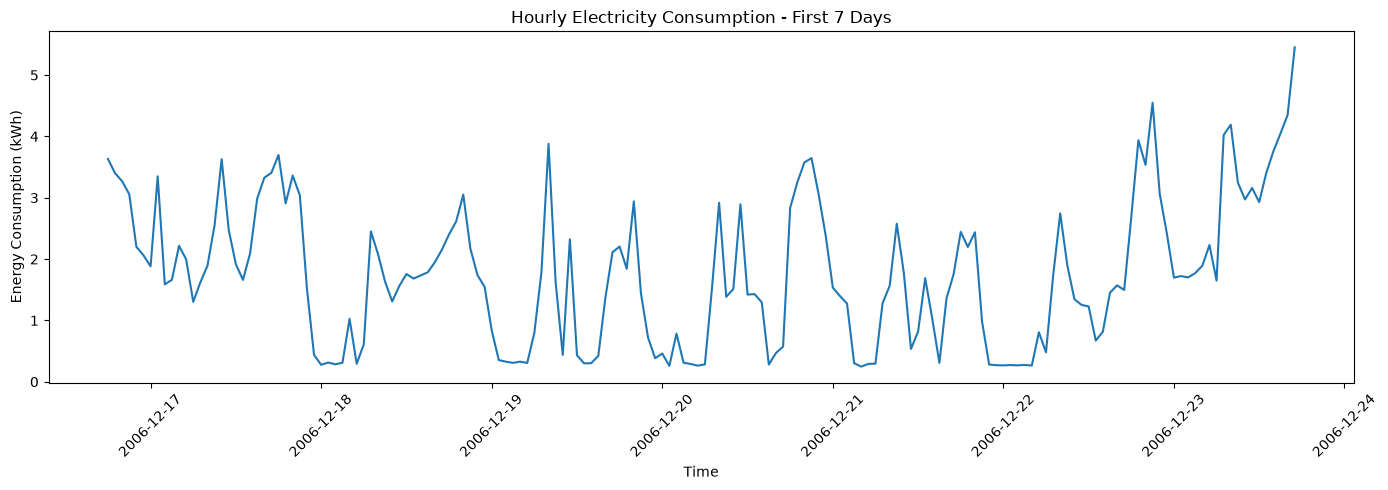

In [26]:
plt.figure(figsize=(14,5))

plt.plot(
    hourly_df.index[:168],
    hourly_df['energy_kwh'][:168]
)

plt.xlabel('Time')
plt.ylabel('Energy Consumption (kWh)')
plt.title('Hourly Electricity Consumption - First 7 Days')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [27]:
hourly_power = minute_data['Global_active_power'].resample('h').mean()

hourly_count = minute_data['Global_active_power'].resample('h').count()

hourly_power = hourly_power.where(hourly_count >= 45)

hourly_df = pd.DataFrame({
    'energy_kwh': hourly_power
})

print(hourly_df.shape)

(34589, 1)


In [28]:
hourly_df['hour'] = hourly_df.index.hour

hourly_df['day_of_week'] = hourly_df.index.dayofweek

hourly_df['month'] = hourly_df.index.month

hourly_df['is_weekend'] = (
    hourly_df['day_of_week'] >= 5
).astype(int)

In [29]:
hourly_df['previous_hour'] = (
    hourly_df['energy_kwh'].shift(1)
)

hourly_df['previous_day'] = (
    hourly_df['energy_kwh'].shift(24)
)

In [30]:
hourly_df['rolling_mean_24'] = (
    hourly_df['energy_kwh']
    .shift(1)
    .rolling(window=24)
    .mean()
)

In [31]:
hourly_df.head(30)

,energy_kwh,hour,day_of_week,month,is_weekend,previous_hour,previous_day,rolling_mean_24
datetime,,,,,,,,
2006-12-16 17:00:00,NaN,17,5,12,1,NaN,NaN,NaN
2006-12-16 18:00:00,3.632200,18,5,12,1,NaN,NaN,NaN
2006-12-16 19:00:00,3.400233,19,5,12,1,3.632200,NaN,NaN
2006-12-16 20:00:00,3.268567,20,5,12,1,3.400233,NaN,NaN
2006-12-16 21:00:00,3.056467,21,5,12,1,3.268567,NaN,NaN
2006-12-16 22:00:00,2.200133,22,5,12,1,3.056467,NaN,NaN
2006-12-16 23:00:00,2.061600,23,5,12,1,2.200133,NaN,NaN
2006-12-17 00:00:00,1.882467,0,6,12,1,2.061600,NaN,NaN
2006-12-17 01:00:00,3.349400,1,6,12,1,1.882467,NaN,NaN


In [32]:
hourly_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 34589 entries, 2006-12-16 17:00:00 to 2010-11-26 21:00:00
Freq: h
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   energy_kwh       34151 non-null  float64
 1   hour             34589 non-null  int32  
 2   day_of_week      34589 non-null  int32  
 3   month            34589 non-null  int32  
 4   is_weekend       34589 non-null  int64  
 5   previous_hour    34151 non-null  float64
 6   previous_day     34128 non-null  float64
 7   rolling_mean_24  33806 non-null  float64
dtypes: float64(4), int32(3), int64(1)
memory usage: 2.0 MB


In [33]:
hourly_df.isnull().sum()

energy_kwh         438
hour                 0
day_of_week          0
month                0
is_weekend           0
previous_hour      438
previous_day       461
rolling_mean_24    783
dtype: int64

In [34]:
ml_df = hourly_df.dropna().copy()

print("Original hourly dataset:", hourly_df.shape)

print("Final ML dataset:", ml_df.shape)

ml_df.head()

Original hourly dataset: (34589, 8)
Final ML dataset: (33791, 8)


,energy_kwh,hour,day_of_week,month,is_weekend,previous_hour,previous_day,rolling_mean_24
datetime,,,,,,,,
2006-12-17 18:00:00,3.697100,18,6,12,1,3.406767,3.632200,2.465140
2006-12-17 19:00:00,2.908400,19,6,12,1,3.697100,3.400233,2.467844
2006-12-17 20:00:00,3.361500,20,6,12,1,2.908400,3.268567,2.447351
2006-12-17 21:00:00,3.040767,21,6,12,1,3.361500,3.056467,2.451224
2006-12-17 22:00:00,1.518000,22,6,12,1,3.040767,2.200133,2.450569


In [35]:
X = ml_df.drop('energy_kwh', axis=1)

y = ml_df['energy_kwh']

In [36]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (33791, 7)
y shape: (33791,)


In [37]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [38]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (27032, 7)
Testing data: (6759, 7)


In [39]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()

In [40]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ 0.01, 0. ,-0. ,..., 0.61, 0.17, 0.06]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['hour','day_of_week','month',...,'previous_hour','previous_day', 'rolling_mean_24']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.06985
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [41]:
y_pred = model.predict(X_test)

In [42]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

print(comparison.head(10))

     Actual  Predicted
0  0.243000   0.397057
1  0.309033   0.412533
2  0.899333   1.499281
3  0.177167   0.357298
4  0.385667   0.555664
5  0.413067   1.479795
6  1.036133   0.609396
7  1.189267   1.379386
8  1.070600   1.439393
9  3.539267   2.165897


In [43]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [44]:
mae = mean_absolute_error(y_test, y_pred)

print("MAE:", mae)

MAE: 0.4308607734100748


In [45]:
mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

print("RMSE:", rmse)

RMSE: 0.6112146572900069


In [46]:
r2 = r2_score(y_test, y_pred)

print("R2 Score:", r2)

R2 Score: 0.5402778351595959


In [47]:
baseline_pred = X_test['previous_hour']

baseline_mae = mean_absolute_error(
    y_test,
    baseline_pred
)

print("Baseline MAE:", baseline_mae)
print("Linear Regression MAE:", mae)

Baseline MAE: 0.4431515447811591
Linear Regression MAE: 0.4308607734100748


In [48]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

In [49]:
dt_model = DecisionTreeRegressor(
    max_depth=8,
    min_samples_leaf=20,
    random_state=42
)

dt_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",8
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with `

In [50]:
dt_pred = dt_model.predict(X_test)

In [51]:
dt_mae = mean_absolute_error(y_test, dt_pred)

dt_rmse = np.sqrt(
    mean_squared_error(y_test, dt_pred)
)

dt_r2 = r2_score(y_test, dt_pred)

print("Decision Tree MAE:", dt_mae)
print("Decision Tree RMSE:", dt_rmse)
print("Decision Tree R2:", dt_r2)

Decision Tree MAE: 0.3799930629584811
Decision Tree RMSE: 0.5700069765818278
Decision Tree R2: 0.6001765475478056


In [52]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [53]:
rf_pred = rf_model.predict(X_test)

In [54]:
rf_mae = mean_absolute_error(y_test, rf_pred)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_pred)
)

rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R2:", rf_r2)

Random Forest MAE: 0.3677866353069027
Random Forest RMSE: 0.5527548580112984
Random Forest R2: 0.6240128011983052


In [55]:
results = pd.DataFrame({
    'Model': [
        'Baseline',
        'Linear Regression',
        'Decision Tree',
        'Random Forest'
    ],

    'MAE': [
        baseline_mae,
        mae,
        dt_mae,
        rf_mae
    ],

    'RMSE': [
        mean_squared_error(
            y_test, baseline_pred
        ) ** 0.5,
        rmse,
        dt_rmse,
        rf_rmse
    ],

    'R2 Score': [
        r2_score(y_test, baseline_pred),
        r2,
        dt_r2,
        rf_r2
    ]
})

results.sort_values(
    by='MAE',
    ascending=True
)

,Model,MAE,RMSE,R2 Score
3,Random Forest,0.367787,0.552755,0.624013
2,Decision Tree,0.379993,0.570007,0.600177
1,Linear Regression,0.430861,0.611215,0.540278
0,Baseline,0.443152,0.688592,0.416512


In [56]:
importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance)

           Feature  Importance
4    previous_hour    0.696289
0             hour    0.121284
5     previous_day    0.070207
6  rolling_mean_24    0.057119
2            month    0.026635
1      day_of_week    0.023480
3       is_weekend    0.004986


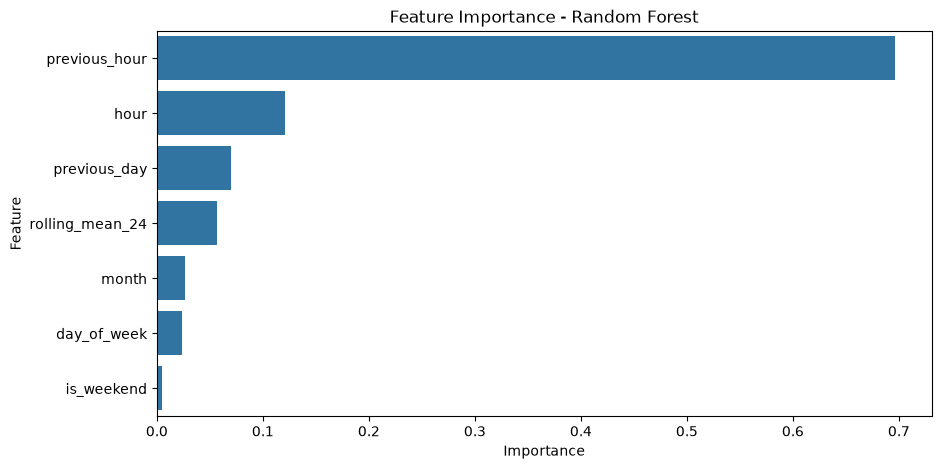

In [57]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance - Random Forest')

plt.show()

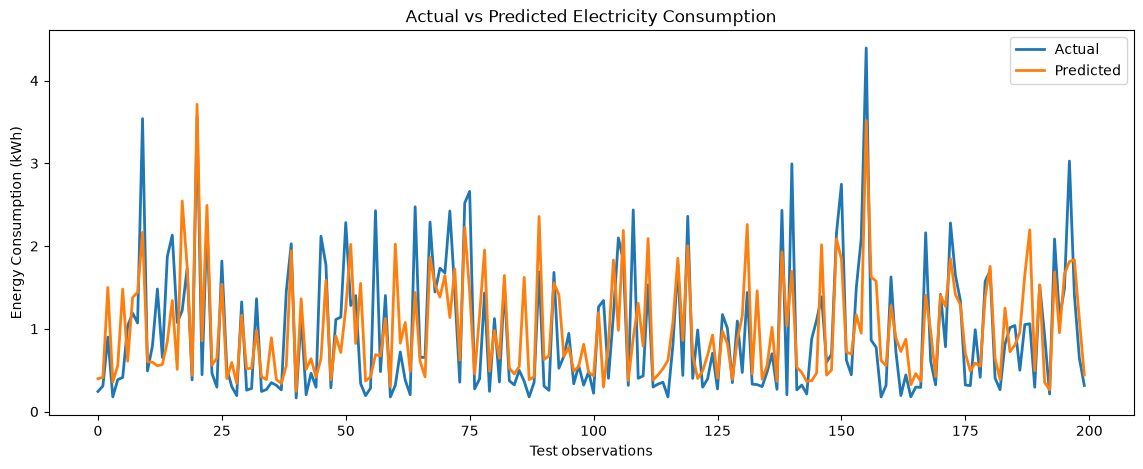

In [60]:
plt.figure(figsize=(14, 5))

plt.plot(
    y_test.values[:200],
    label='Actual',
    linewidth=2
)

plt.plot(
    y_pred[:200],
    label='Predicted',
    linewidth=2
)

plt.title('Actual vs Predicted Electricity Consumption')

plt.xlabel('Test observations')
plt.ylabel('Energy Consumption (kWh)')

plt.legend()
plt.show()

In [61]:
hourly_df['hour_sin'] = np.sin(
    2 * np.pi * hourly_df['hour'] / 24
)

hourly_df['hour_cos'] = np.cos(
    2 * np.pi * hourly_df['hour'] / 24
)

In [62]:
hourly_df['day_sin'] = np.sin(
    2 * np.pi * hourly_df['day_of_week'] / 7
)

hourly_df['day_cos'] = np.cos(
    2 * np.pi * hourly_df['day_of_week'] / 7
)

In [63]:
# Cyclical encoding for hour
hourly_df['hour_sin'] = np.sin(
    2 * np.pi * hourly_df['hour'] / 24
)

hourly_df['hour_cos'] = np.cos(
    2 * np.pi * hourly_df['hour'] / 24
)

# Cyclical encoding for day of week
hourly_df['day_sin'] = np.sin(
    2 * np.pi * hourly_df['day_of_week'] / 7
)

hourly_df['day_cos'] = np.cos(
    2 * np.pi * hourly_df['day_of_week'] / 7
)

# Cyclical encoding for month
hourly_df['month_sin'] = np.sin(
    2 * np.pi * hourly_df['month'] / 12
)

hourly_df['month_cos'] = np.cos(
    2 * np.pi * hourly_df['month'] / 12
)

In [64]:
ml_df_v2 = hourly_df.dropna().copy()

features_v2 = [
    'is_weekend',
    'previous_hour',
    'previous_day',
    'rolling_mean_24',
    'hour_sin',
    'hour_cos',
    'day_sin',
    'day_cos',
    'month_sin',
    'month_cos'
]

X_v2 = ml_df_v2[features_v2]

y_v2 = ml_df_v2['energy_kwh']

print("New dataset:", X_v2.shape)

New dataset: (33791, 10)


In [65]:
from sklearn.model_selection import train_test_split
X_train_v2, X_test_v2, y_train_v2, y_test_v2 = train_test_split(
    X_v2,
    y_v2,
    test_size=0.2,
    shuffle=False
)

In [66]:
print("Training features:", X_train_v2.shape)
print("Testing features:", X_test_v2.shape)

print("Training target:", y_train_v2.shape)
print("Testing target:", y_test_v2.shape)

Training features: (27032, 10)
Testing features: (6759, 10)
Training target: (27032,)
Testing target: (6759,)


In [67]:
rf_model_v2 = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model_v2.fit(X_train_v2, y_train_v2)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [68]:
y_pred_v2 = rf_model_v2.predict(X_test_v2)

mae_v2 = mean_absolute_error(y_test_v2, y_pred_v2)

rmse_v2 = np.sqrt(
    mean_squared_error(y_test_v2, y_pred_v2)
)

r2_v2 = r2_score(y_test_v2, y_pred_v2)

print("Improved Random Forest Results")
print("MAE:", mae_v2)
print("RMSE:", rmse_v2)
print("R2:", r2_v2)

Improved Random Forest Results
MAE: 0.3372913086143635
RMSE: 0.4839428787246778
R2: 0.5780360326134528


In [69]:
comparison = pd.DataFrame({
    'Model': [
        'Original Random Forest',
        'Improved Random Forest'
    ],
    'MAE': [
        rf_mae,
        mae_v2
    ],
    'RMSE': [
        rf_rmse,
        rmse_v2
    ],
    'R2': [
        rf_r2,
        r2_v2
    ]
})

print(comparison)

                    Model       MAE      RMSE        R2
0  Original Random Forest  0.367787  0.552755  0.624013
1  Improved Random Forest  0.337291  0.483943  0.578036


In [70]:
from sklearn.ensemble import RandomForestRegressor

rf_model_v2 = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model_v2.fit(X_train_v2, y_train_v2)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [71]:
y_pred_v2 = rf_model_v2.predict(X_test_v2)

In [72]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_v2 = mean_absolute_error(y_test_v2, y_pred_v2)
rmse_v2 = np.sqrt(mean_squared_error(y_test_v2, y_pred_v2))
r2_v2 = r2_score(y_test_v2, y_pred_v2)

print("Improved Random Forest Results")
print("------------------------------")
print("MAE:", mae_v2)
print("RMSE:", rmse_v2)
print("R2 Score:", r2_v2)

Improved Random Forest Results
------------------------------
MAE: 0.33729130861436346
RMSE: 0.4839428787246778
R2 Score: 0.5780360326134528


In [73]:
comparison = pd.DataFrame({
    'Model': ['Random Forest (Original)', 'Random Forest (Improved)'],
    'MAE': [0.367787, mae_v2],
    'RMSE': [0.552755, rmse_v2],
    'R2 Score': [0.624013, r2_v2]
})

comparison

,Model,MAE,RMSE,R2 Score
0,Random Forest (Original),0.367787,0.552755,0.624013
1,Random Forest (Improved),0.337291,0.483943,0.578036


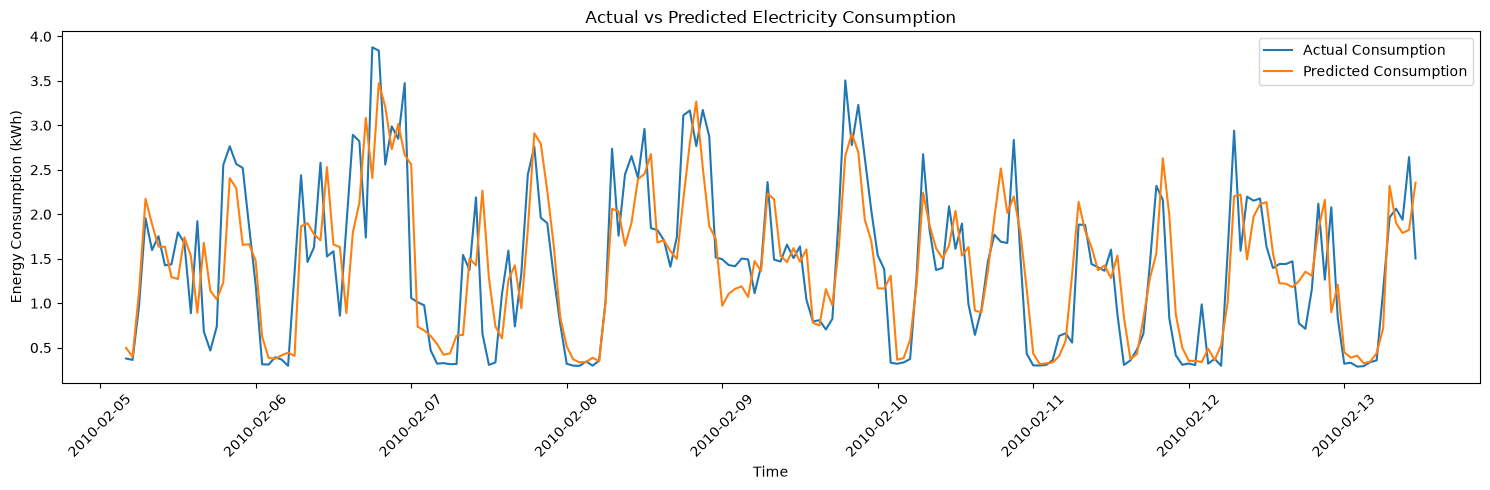

In [74]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(
    y_test_v2.index[:200],
    y_test_v2.iloc[:200],
    label='Actual Consumption'
)

plt.plot(
    y_test_v2.index[:200],
    y_pred_v2[:200],
    label='Predicted Consumption'
)

plt.title('Actual vs Predicted Electricity Consumption')
plt.xlabel('Time')
plt.ylabel('Energy Consumption (kWh)')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

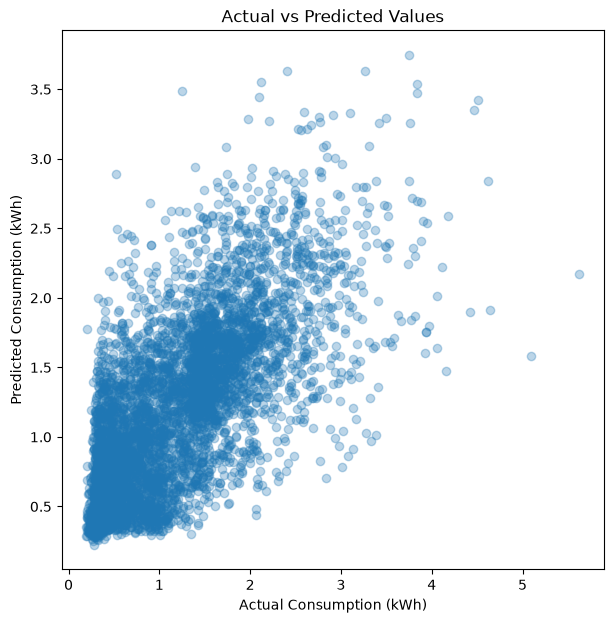

In [75]:
plt.figure(figsize=(7, 7))

plt.scatter(y_test_v2, y_pred_v2, alpha=0.3)

plt.xlabel('Actual Consumption (kWh)')
plt.ylabel('Predicted Consumption (kWh)')
plt.title('Actual vs Predicted Values')

plt.show()

In [76]:
feature_importance = pd.DataFrame({
    'Feature': X_train_v2.columns,
    'Importance': rf_model_v2.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance

,Feature,Importance
1,previous_hour,0.690364
2,previous_day,0.076430
5,hour_cos,0.058625
4,hour_sin,0.054490
3,rolling_mean_24,0.052476
9,month_cos,0.020357
6,day_sin,0.019792
8,month_sin,0.013904
7,day_cos,0.009209
0,is_weekend,0.004353


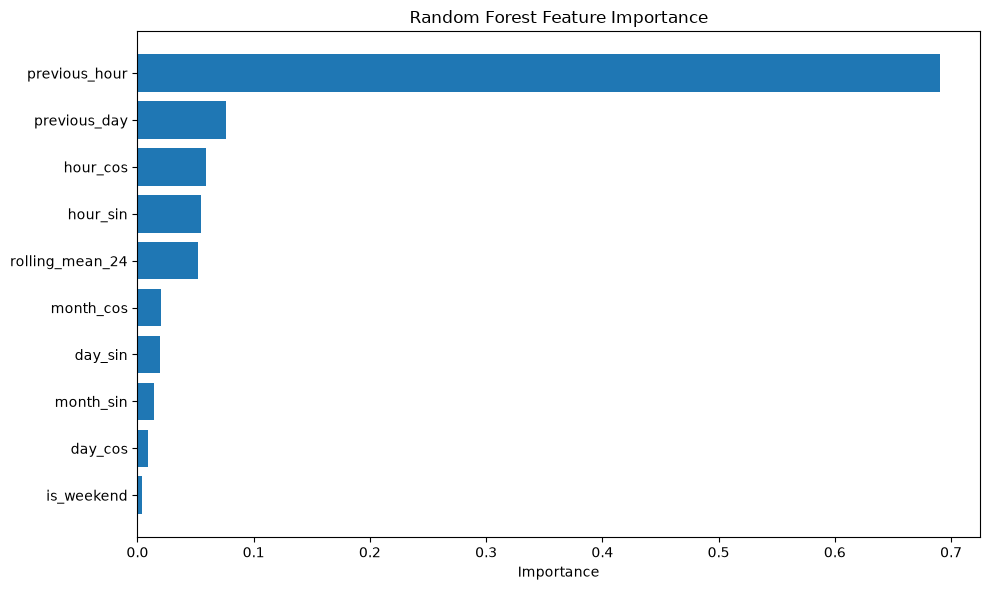

In [77]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.xlabel('Importance')
plt.title('Random Forest Feature Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [78]:
import joblib
import os

In [79]:
os.makedirs('../models', exist_ok=True)

In [80]:
import gzip
import joblib

with gzip.open('../models/random_forest_model.pkl.gz', 'wb') as f:
    joblib.dump(rf_model_v2, f)

['../models/random_forest_model.pkl']

In [81]:
joblib.dump(
    list(X_train_v2.columns),
    '../models/model_features.pkl'
)

['../models/model_features.pkl']

In [82]:
with gzip.open('../models/random_forest_model.pkl.gz', 'rb') as f:
    loaded_model = joblib.load(f)

test_predictions = loaded_model.predict(X_test_v2)

print("Original prediction:", y_pred_v2[0])
print("Loaded model prediction:", test_predictions[0])

Original prediction: 0.49733777500295434
Loaded model prediction: 0.49733777500295434


In [83]:
comparison.to_csv('../models/model_comparison.csv', index=False)

print("Model and evaluation results saved successfully!")

Model and evaluation results saved successfully!


In [84]:
import joblib
import pandas as pd
import numpy as np

with gzip.open('../models/random_forest_model.pkl.gz', 'rb') as f:
    loaded_model = joblib.load(f)
model_features = joblib.load('../models/model_features.pkl')

In [85]:
def predict_energy(
    previous_hour,
    previous_day,
    rolling_mean_24,
    hour,
    day_of_week,
    month
):
    is_weekend = int(day_of_week >= 5)

    input_data = pd.DataFrame([{
        'is_weekend': is_weekend,
        'previous_hour': previous_hour,
        'previous_day': previous_day,
        'rolling_mean_24': rolling_mean_24,
        'hour_sin': np.sin(2 * np.pi * hour / 24),
        'hour_cos': np.cos(2 * np.pi * hour / 24),
        'day_sin': np.sin(2 * np.pi * day_of_week / 7),
        'day_cos': np.cos(2 * np.pi * day_of_week / 7),
        'month_sin': np.sin(2 * np.pi * month / 12),
        'month_cos': np.cos(2 * np.pi * month / 12)
    }])

    input_data = input_data[model_features]

    prediction = loaded_model.predict(input_data)

    return prediction[0]

In [86]:
prediction = predict_energy(
    previous_hour=1.5,
    previous_day=1.8,
    rolling_mean_24=1.6,
    hour=18,
    day_of_week=2,
    month=6
)

print("Predicted electricity consumption:", prediction, "kWh")

Predicted electricity consumption: 1.5934197299428383 kWh


In [87]:
sample_input = X_test_v2.iloc[[0]]

real_prediction = loaded_model.predict(sample_input)[0]

print("Actual consumption:", y_test_v2.iloc[0], "kWh")
print("Predicted consumption:", real_prediction, "kWh")

Actual consumption: 0.378 kWh
Predicted consumption: 0.4973377750029544 kWh


In [88]:
!pip install streamlit

In [89]:
ml_df.to_csv(
    "../dataset/processed_hourly_data.csv",
    index=True
)